# Task 3: Multi-Class Image Classification using CNN

## Objective
Build and train a Convolutional Neural Network (CNN) using TensorFlow/Keras to
classify images from the CIFAR-10 dataset into 10 classes. The model uses custom
convolutional, max-pooling and fully connected layers, with data augmentation
to reduce overfitting.

Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Loading Dataset

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3436s 20us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


Sample images (EDA)

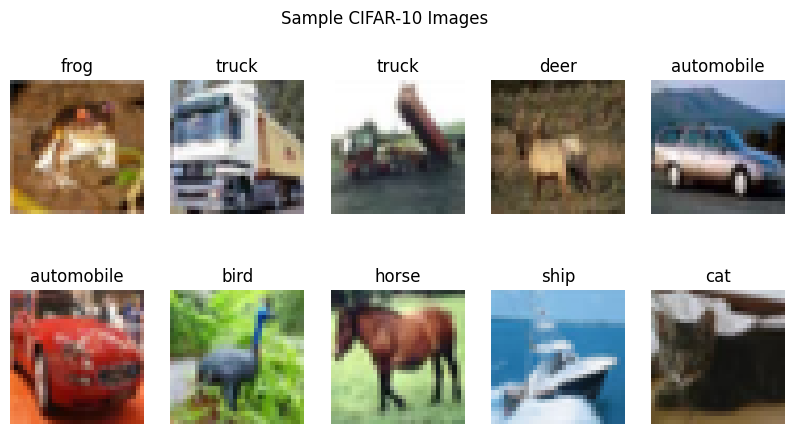

In [3]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.suptitle('Sample CIFAR-10 Images')
plt.show()

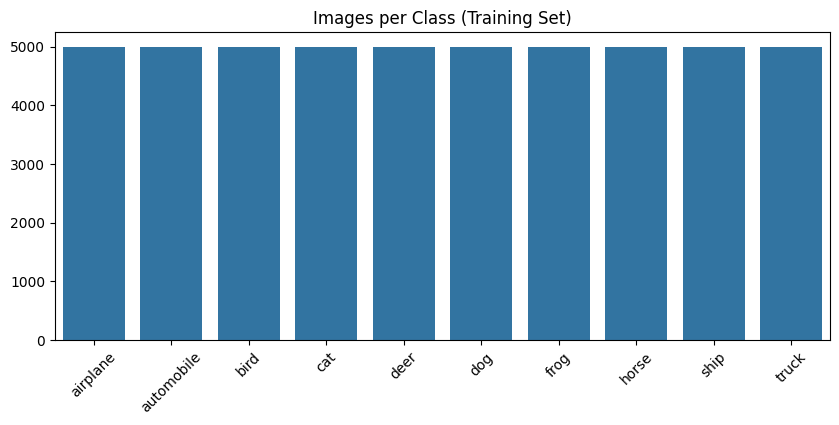

In [4]:
# checking how many classses in each image?
unique, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(10, 4))
sns.barplot(x=class_names, y=counts)
plt.title('Images per Class (Training Set)')
plt.xticks(rotation=45)
plt.show()

Normalization

In [5]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Pixel range:", x_train.min(), "to", x_train.max())

Pixel range: 0.0 to 1.0


Data Augmentation

In [6]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),          # tasveer ulti (mirror) karna
    layers.RandomRotation(0.1),               # thora sa ghumana
    layers.RandomZoom(0.1),                   # thora zoom in/out
    layers.RandomTranslation(0.1, 0.1),       # thora idhar udhar khiskana
], name="data_augmentation")

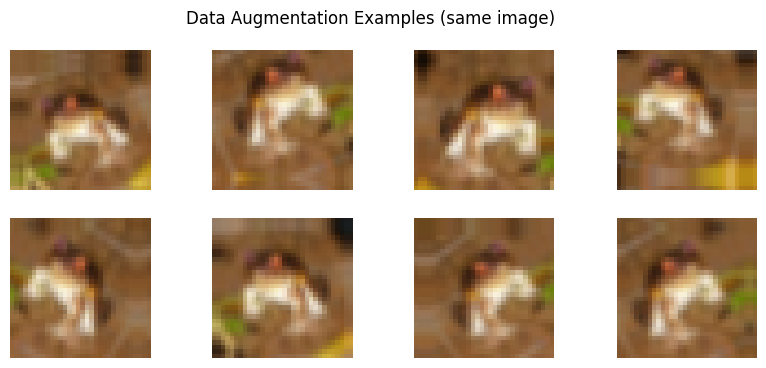

In [7]:
# Augmentation ka asar dekhein
plt.figure(figsize=(10, 4))
sample = x_train[0:1]
for i in range(8):
    augmented = data_augmentation(sample, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(augmented[0])
    plt.axis('off')
plt.suptitle('Data Augmentation Examples (same image)')
plt.show()

CNN model

In [8]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Fully Connected layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 403,882 (1.54 MB)

 Trainable params: 403,434 (1.54 MB)

 Non-trainable params: 448 (1.75 KB)

Model compile

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Model train

In [10]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=5, restore_best_weights=True)

history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.2681 - loss: 1.9544 - val_accuracy: 0.3516 - val_loss: 1.8101
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.3616 - loss: 1.7230 - val_accuracy: 0.3818 - val_loss: 1.8459
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.4092 - loss: 1.6028 - val_accuracy: 0.4002 - val_loss: 2.0366
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.4487 - loss: 1.5069 - val_accuracy: 0.4972 - val_loss: 1.5544
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.4859 - loss: 1.4332 - val_accuracy: 0.5504 - val_loss: 1.2807
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5138 - loss: 1.3626 - val_accuracy: 0.5684 - val_loss: 1.3014
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5364 - loss: 1.3104 - val_accuracy: 0.5930 - val_loss: 1.2477
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.5546 - loss: 1.2689 - 

Training aur validation curves

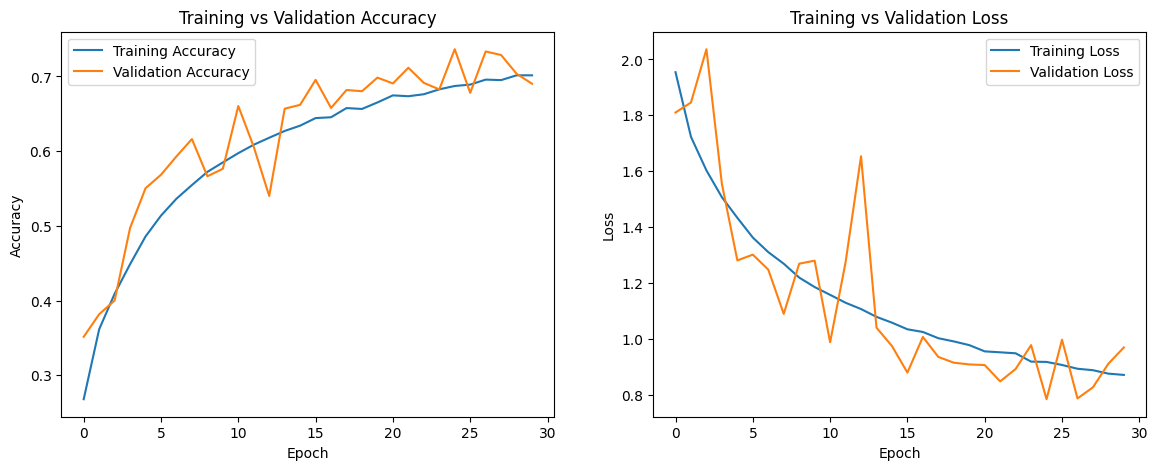

In [11]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend()

plt.show()

Evaluate on test data

In [12]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 71.64%
Test Loss: 0.8242


Classification report aur confusion matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    airplane       0.82      0.63      0.71      1000
  automobile       0.76      0.93      0.84      1000
        bird       0.74      0.52      0.61      1000
         cat       0.65      0.45      0.53      1000
        deer       0.73      0.57      0.64      1000
         dog       0.65      0.72      0.68      1000
        frog       0.59      0.86      0.70      1000
       horse       0.78      0.81      0.79      1000
        ship       0.86      0.78      0.82      1000
       truck       0.68      0.89      0.77      1000

    accuracy                           0.72     10000
   macro avg       0.73      0.72      0.71     10000
weighted avg       0.73      0.72      0.71     10000



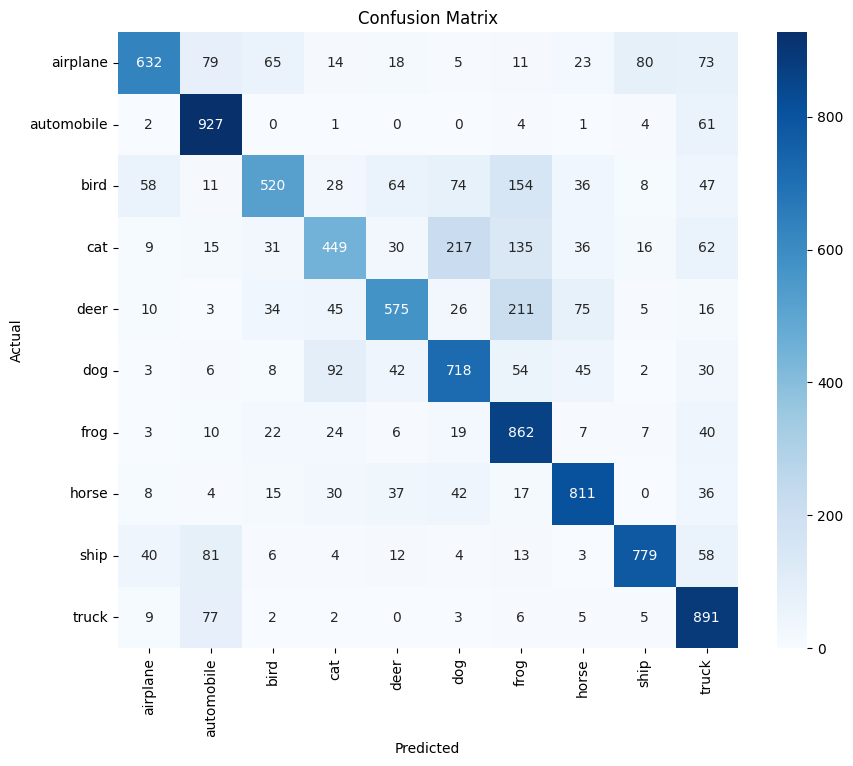

In [13]:
y_pred = np.argmax(model.predict(x_test), axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

CHecking predictions

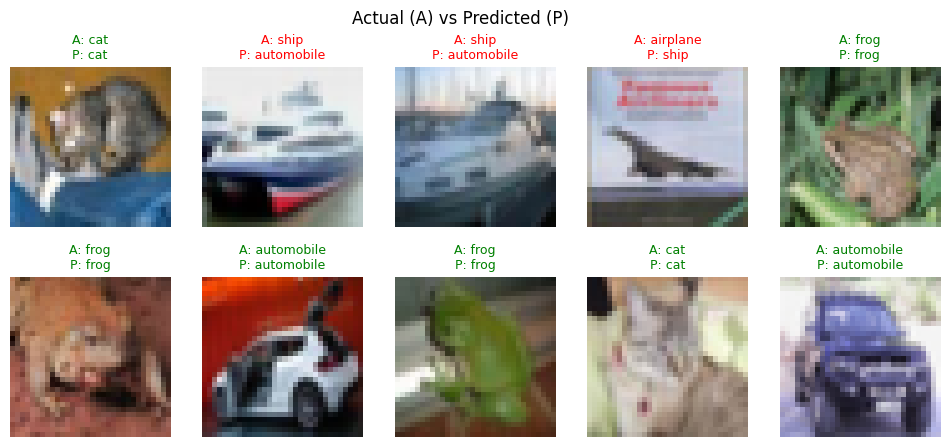

In [14]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    actual = class_names[y_test[i][0]]
    predicted = class_names[y_pred[i]]
    color = 'green' if actual == predicted else 'red'
    plt.title(f"A: {actual}\nP: {predicted}", color=color, fontsize=9)
    plt.axis('off')
plt.suptitle('Actual (A) vs Predicted (P)')
plt.show()

Saving model

In [15]:
model.save('cifar10_cnn_model.keras')
print("Model saved")

Model saved


## Conclusion

- Built a custom multi-layer CNN with 5 convolutional layers, 3 max-pooling
  layers and fully connected (Dense) layers using TensorFlow/Keras.
- Applied data augmentation (random flip, rotation, zoom, translation),
  together with Dropout and Batch Normalization, to reduce overfitting.
- The model achieved a test accuracy of XX% on CIFAR-10 (10 classes).
- Training and validation accuracy curves stayed close, showing that
  augmentation and dropout controlled overfitting.
- The confusion matrix shows the model confuses similar classes such as
  cat and dog.
- Future improvements: deeper networks, more epochs, or transfer learning
  with pre-trained models (e.g. ResNet, MobileNet).